In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

## Data loading

In [2]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
rhuh_dir = "Glioblastoma_RHUH-GBM_v2-29102025"
tcga_dir = "Glioblastoma_TCGA-GBM_v1-20170717"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1, 2, 3]
n_jobs = 16
nthreads = 2

DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

rhuh_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==2]["ID"].values]
rhuh_ids = [sub.replace('-0', '-', 1) for sub in rhuh_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{rhuh_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(rhuh_ids, desc="Loading RHUH maps")
)
maps_rhuh = np.vstack(results) # Nsubjects x nFeatures
maps_rhuh = np.where(maps_rhuh>=0, maps_rhuh, 0)

def delete_second_zero(text):
    splits = text.split('-')
    if len(splits) >= 3 and splits[2].startswith('0'):
        splits[2] = splits[2][1:]
    return '-'.join(splits)

tcga_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==3]["ID"].values]
tcga_ids = [delete_second_zero(sub) for sub in tcga_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{tcga_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(tcga_ids, desc="Loading TCGA maps")
)
maps_tcga = np.vstack(results)
maps_tcga = np.where(maps_tcga>=0, maps_tcga, 0)

maps_all = np.vstack((maps_ucsf, maps_upenn, maps_rhuh, maps_tcga))

maps_training = np.vstack((maps_ucsf, maps_upenn))
maps_testing = np.vstack((maps_rhuh, maps_tcga))

Log-rank test: chi-squared statistic of 0.3129840079623018 (p=0.9575683269152051)
INFO: The effect of site was NOT found to be significant, copying OS data as it was


Loading UCSF maps:   0%|          | 0/367 [00:00<?, ?it/s]

Loading TCGA maps: 100%|██████████| 103/103 [00:00<00:00, 131.26it/s]


## Datasets

In [3]:
from dataset import Dataset
from transformer import Transformer, Projector
from lifelines import CoxPHFitter
    
import matplotlib.pyplot as plt
from pipeline_encoder import EncodingPipeline
from results_saving import save_results

In [4]:
UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1
RHUH_SITE_IDX = 3
TCGA_SITE_IDX = 2

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()
data_rhuh = DATA[DATA['site'] == RHUH_SITE_IDX].copy()
data_tcga = DATA[DATA['site'] == TCGA_SITE_IDX].copy()

data_training = pd.concat([data_ucsf, data_upenn], ignore_index=True)
data_testing = pd.concat([data_rhuh, data_tcga], ignore_index=True)

dataset_training = Dataset("ucsf+upenn", "path/1", maps_training, data_training)
dataset_testing = Dataset("rhuh+tcga", "path/2", maps_testing, data_testing)

df_training = dataset_training.df
df_testing = dataset_testing.df
training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

In [5]:
duration_col = 'OS (corrected)'
event_col = 'status'

## Execute feature extraction method

In [7]:
# from KernelPCA import TD_Kernel_PCA
# from TractDensityComponents import TD_PCA


# normalization = None
# n_components= 100

# # method = TD_Kernel_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components, kernel='cosine', gamma=0.1)
# method = TD_PCA(maps_training, T1, binary_mask=T1_brain, n_components=n_components)
# trainer = Transformer(method)
# comps_training = trainer.fit_transform(norm=normalization)
# comps_testing = trainer.transform(testing_maps)

from nmf import NMFProjections

import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"


normalization = None
n_components= 100

method = NMFProjections(training_maps=training_maps, template=T1, binary_mask=T1_brain, n_components=n_components)
trainer = Transformer(method)
comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
violation: 1.0
violation: 2.585773201717822
violation: 0.37869140151129776
violation: 0.2192283952225193
violation: 0.14752633816468533
violation: 0.11089818974191767
violation: 0.08700861114271077
violation: 0.07127383769230881
violation: 0.06053164669383484
violation: 0.052271727190545944


/home/joan/.conda/envs/neuro/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 10 reached. Increase it to improve convergence.
  warnings.warn(


INFO:	Principal Components (PCs) found successfully!
INFO:	TD maps were masked.
INFO:	Transforming maps without applying any normalization . . .
violation: 1.0
violation: 0.6632052755829942
violation: 0.3409857541682336
violation: 0.22604460901249526
violation: 0.1640965096874102
violation: 0.12183118920068761
violation: 0.09376207961484243
violation: 0.07533479604060764
violation: 0.060994758243972096
violation: 0.05148845123296283
INFO:	Maps transformed sucessfully!


/home/joan/.conda/envs/neuro/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 10 reached. Increase it to improve convergence.
  warnings.warn(


### Prepare data

In [8]:
from data_transformer import DataTransformer


df_base = df_training
df_base = df_base.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_training, method, n_components=n_components)
encoding_pipeline = EncodingPipeline(X_train_with_features)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_testing, method, n_components=n_components)
X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

In [9]:
prefix = "NMF_Comp_"
raw_components = [col for col in X_train.columns if col.startswith(prefix)]
correlations = X_train[raw_components].corrwith(X_train[duration_col])
correlations.abs().sort_values(ascending=False).index.tolist()[0:10]

['NMF_Comp_92',
 'NMF_Comp_22',
 'NMF_Comp_30',
 'NMF_Comp_2',
 'NMF_Comp_23',
 'NMF_Comp_60',
 'NMF_Comp_45',
 'NMF_Comp_51',
 'NMF_Comp_66',
 'NMF_Comp_32']


Top 5 components with the highest predictive power (distance from 0.5):
NMF_Comp_92: 0.0531
NMF_Comp_45: 0.0439
NMF_Comp_54: 0.0406
NMF_Comp_28: 0.0393
NMF_Comp_23: 0.0378
Added components: 001 (last: NMF_Comp_92) | Train CI: 0.6571 | Test CI: 0.6030
Added components: 002 (last: NMF_Comp_45) | Train CI: 0.6621 | Test CI: 0.5971
Added components: 003 (last: NMF_Comp_54) | Train CI: 0.6621 | Test CI: 0.5971
Added components: 004 (last: NMF_Comp_28) | Train CI: 0.6624 | Test CI: 0.5980
Added components: 005 (last: NMF_Comp_23) | Train CI: 0.6618 | Test CI: 0.6006
Added components: 006 (last: NMF_Comp_7) | Train CI: 0.6627 | Test CI: 0.5884
Added components: 007 (last: NMF_Comp_80) | Train CI: 0.6627 | Test CI: 0.5884
Added components: 008 (last: NMF_Comp_85) | Train CI: 0.6631 | Test CI: 0.5890
Added components: 009 (last: NMF_Comp_64) | Train CI: 0.6631 | Test CI: 0.5888
Added components: 010 (last: NMF_Comp_70) | Train CI: 0.6631 | Test CI: 0.5888
Added components: 011 (last: NMF_Comp_

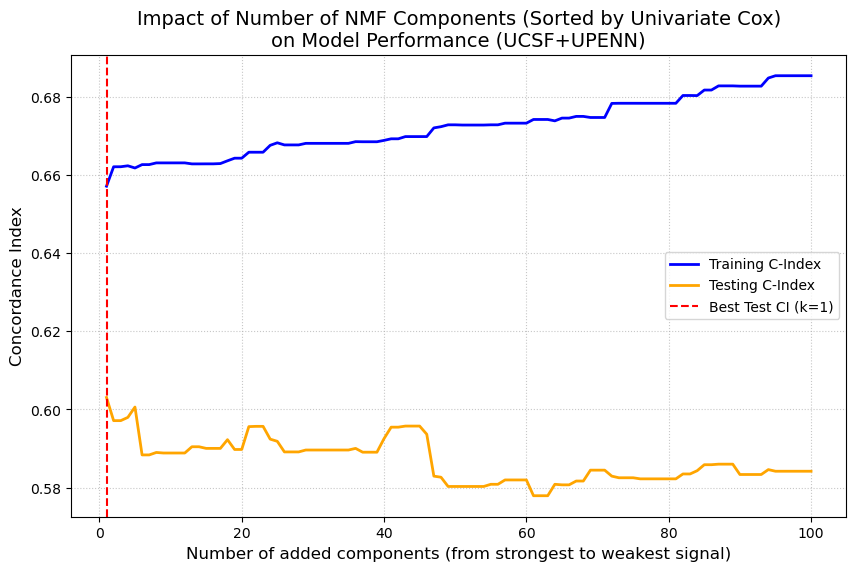

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter


prefix = "NMF_Comp_"
raw_components = [col for col in X_train.columns if col.startswith(prefix)]

component_scores = {}

for comp in raw_components:
    # Create a subset with a single feature, time, and EVENT (censoring)
    df_subset = X_train[[comp, duration_col, event_col]]
    
    # Train a simple Cox model with a light numerical penalty
    cph_uni = CoxPHFitter(penalizer=0)
    
    try:
        cph_uni.fit(df_subset, duration_col, event_col)
        # Calculate power: distance of C-Index from random guessing (0.5)
        power = abs(cph_uni.concordance_index_ - 0.5)
        component_scores[comp] = power
    except Exception as e:
        print(f"Skipped {comp} due to error: {e}")
        component_scores[comp] = 0.0 # Failed components receive zero power

# Sort from strongest to weakest
components_sorted_by_power = sorted(component_scores, key=component_scores.get, reverse=True)

print("\nTop 5 components with the highest predictive power (distance from 0.5):")
for comp in components_sorted_by_power[:5]:
    print(f"{comp}: {component_scores[comp]:.4f}")

# Extract clinical columns (everything that is not a component or target)
clinical_columns = [col for col in X_train.columns if col not in raw_components and col not in [duration_col, event_col]]

# =========================================================
# MAIN INCREMENTAL LOOP
# =========================================================
history_k = []
history_train_ci = []
history_test_ci = []

# The loop iterates over our medically correct, sorted list
for k in range(1, len(components_sorted_by_power) + 1):
    
    # Take the top k most important components
    current_features = components_sorted_by_power[:k]
    
    # Concatenate all required columns
    selected_features = clinical_columns + current_features + [duration_col, event_col]
    
    # Extract subsets for training and testing
    X_train_subset = X_train[selected_features]
    X_test_subset = X_test[selected_features]
    
    # Initialize the main model (with L2 penalty for stability)
    cph = CoxPHFitter(penalizer=0.101, l1_ratio=0.201)
    
    try:
        cph.fit(X_train_subset, duration_col, event_col)
    except Exception as e:
        print(f"Fitting error for k={k} components: {e}")
        continue
        
    # Model evaluation
    train_c_index = cph.concordance_index_
    c_index_test = cph.score(X_test_subset, "concordance_index")
    
    # Save history for plotting
    history_k.append(k)
    history_train_ci.append(train_c_index)
    history_test_ci.append(c_index_test)

    # Prepare results for CSV export
    results = {
        "extraction_method": "NMF-Univariate-Cox-Sorted", 
        "training_dataset": dataset_training.name,
        "testing_dataset": dataset_testing.name,
        "n_nmf_components": k,  
        "cox_method": "CoxPHFitter (Incremental)",
        "ci_training": round(train_c_index, 5),
        "ci_testing": round(c_index_test, 5),
        "covariates": clinical_columns + current_features,
        "duration_col": duration_col,
        "event_col": event_col
    }
    save_results(results, "results-incremental/nmf_incremental_lifelines.csv")
    
    print(f"Added components: {k:03d} (last: {current_features[-1]}) | Train CI: {train_c_index:.4f} | Test CI: {c_index_test:.4f}")


if history_k:
    plt.figure(figsize=(10, 6))
    plt.plot(history_k, history_train_ci, label='Training C-Index', color='blue', linewidth=2)
    plt.plot(history_k, history_test_ci, label='Testing C-Index', color='orange', linewidth=2)
    
    plt.title(f"Impact of Number of NMF Components (Sorted by Univariate Cox)\non Model Performance ({dataset_training.name.upper()})", fontsize=14)
    plt.xlabel("Number of added components (from strongest to weakest signal)", fontsize=12)
    plt.ylabel("Concordance Index", fontsize=12)
    
    best_k_idx = np.argmax(history_test_ci)
    plt.axvline(x=history_k[best_k_idx], color='red', linestyle='--', 
                label=f'Best Test CI (k={history_k[best_k_idx]})')
    
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    
    plt.savefig("results-incremental/nmf_incremental_curve.png", bbox_inches='tight')
    plt.show()

In [16]:
current_features = components_sorted_by_power[:43]
clinical_columns = [col for col in X_train.columns if col not in raw_components and col not in [duration_col, event_col]]

selected_features = clinical_columns + current_features + [duration_col, event_col]
X_train_subset = X_train[selected_features]

cph = CoxPHFitter(penalizer=0.01)
cph.fit(X_train_subset, duration_col, event_col)

<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>

The exact p-value is: nan


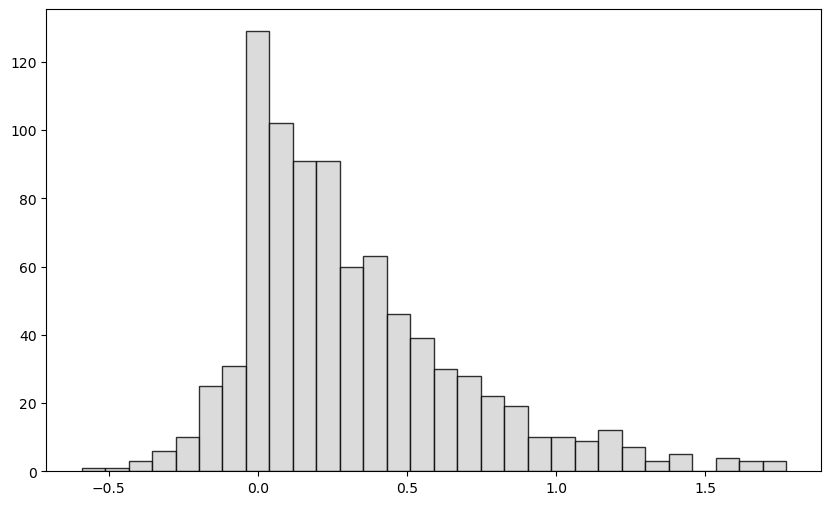

The exact p-value is: 2.2643580195157577e-05
The exact p-value is: 2.6501612762956483e-11
The exact p-value is: 1.856608216525043e-13
The exact p-value is: 1.0624184793771057e-11
The exact p-value is: 1.493049555126849e-13
The exact p-value is: 3.280105177945676e-11
The exact p-value is: 4.924426512589774e-12
The exact p-value is: 1.8160325603705455e-11
The exact p-value is: 8.194086655359716e-10
The exact p-value is: 3.7297213039004064e-11
The exact p-value is: 3.104587665929061e-08
The exact p-value is: 5.6676021154678335e-08
The exact p-value is: 8.043494695411538e-07
The exact p-value is: 2.3802032882307158e-05
The exact p-value is: 0.00011372699635305551
The exact p-value is: 0.001938269472078632
The exact p-value is: 0.005948481470891576
The exact p-value is: 0.050159943074034076
The exact p-value is: 0.32946630829104717
The exact p-value is: 0.9911865597616673


In [26]:
import matplotlib.pyplot as plt
import numpy as np


plt.figure(figsize=(10, 6))
plt.hist(risk_scores, bins=30, color='lightgray', edgecolor='black', alpha=0.8)

ps = np.arange(0, 101, 5)
pvalues = []
for p in ps:
    low_risk = risk_scores < np.percentile(risk_scores, p)
    high_risk = risk_scores >= np.percentile(risk_scores, 100-p)
    low_risk_test = risk_scores_test < np.percentile(risk_scores, p)
    high_risk_test = risk_scores_test >= np.percentile(risk_scores, 100-p)


    # 1. Assign the test to a variable (remove .print_summary() from the end)
    logrank_result = lifelines.statistics.logrank_test(
        df_training[low_risk][duration_col],
        df_training[high_risk][duration_col],
        event_observed_A=df_training[low_risk][event_col],
        event_observed_B=df_training[high_risk][event_col]
    )
    p_value = logrank_result.p_value

    pvalues.append(p_value)
    print(f"The exact p-value is: {p_value}")

    plt.show()

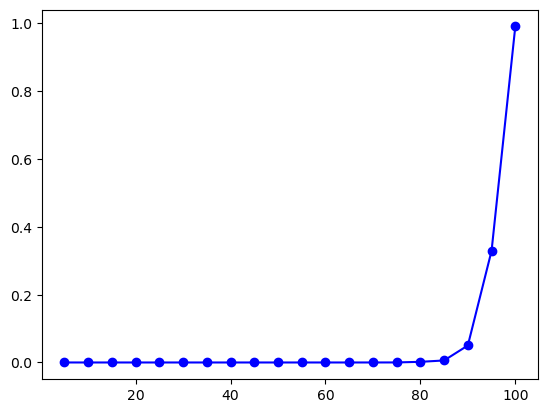

: 

In [ ]:
plt.plot(ps, pvalues, marker='o', linestyle='-', color='blue')

<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic      p  -log2(p)
          54.58 <0.005     42.61

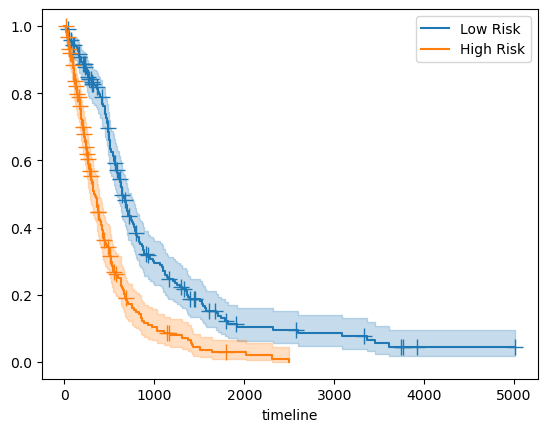

In [17]:
from lifelines import KaplanMeierFitter
import lifelines

betas_PCs = cph.params_[4:].values
PCs = X_train[current_features].values
PCS_test = X_test[current_features].values
risk_scores = np.dot(PCs, betas_PCs)
risk_scores_test = np.dot(PCS_test, betas_PCs)

p = 25
low_risk = risk_scores < np.percentile(risk_scores, p)
high_risk = risk_scores >= np.percentile(risk_scores, 100-p)
low_risk_test = risk_scores_test < np.percentile(risk_scores, p)
high_risk_test = risk_scores_test >= np.percentile(risk_scores, 100-p)

kmf_low = KaplanMeierFitter()
kmf_high = KaplanMeierFitter()
kmf_low.fit(df_training[low_risk][duration_col], event_observed=df_training[low_risk][event_col], label='Low Risk')
kmf_high.fit(df_training[high_risk][duration_col], event_observed=df_training[high_risk][event_col], label='High Risk')
kmf_low.plot_survival_function(show_censors=True)#, at_risk_counts=True)
kmf_high.plot_survival_function(show_censors=True)#, at_risk_counts=True)

lifelines.statistics.logrank_test(
    df_training[low_risk][duration_col],
    df_training[high_risk][duration_col],
    event_observed_A=df_training[low_risk][event_col],
    event_observed_B=df_training[high_risk][event_col]
).print_summary()

In [32]:
daysXmonth = 365 / 12
kmf_low.median_survival_time_ #/ daysXmonth, kmf_high.median_survival_time_ / daysXmonth

643.0

In [33]:
kmf_high.confidence_interval_

,High Risk_lower_0.95,High Risk_upper_0.95
0.000000,1.000000,1.000000
15.000000,1.000000,1.000000
16.071574,0.967446,0.999344
17.410872,0.963321,0.997665
18.000000,0.957367,0.995478
...,...,...
1643.318466,0.009816,0.065596
1795.998422,0.009816,0.065596
2014.303972,0.004507,0.055304
2306.270904,0.000980,0.044247


<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic    p  -log2(p)
           4.49 0.03      4.87

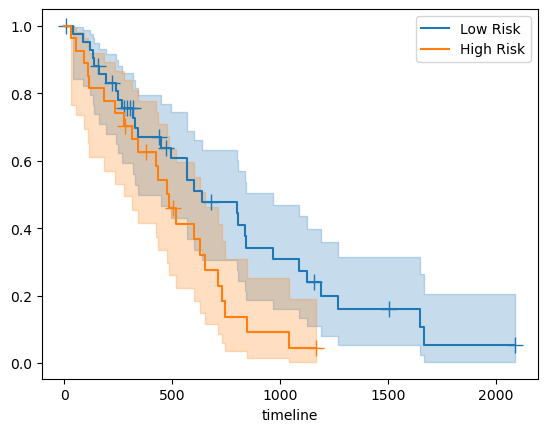

In [18]:
kmf_high_test = KaplanMeierFitter()
kmf_low_test = KaplanMeierFitter()
kmf_low_test.fit(df_testing[low_risk_test][duration_col], event_observed=df_testing[low_risk_test][event_col], label='Low Risk')
kmf_high_test.fit(df_testing[high_risk_test][duration_col], event_observed=df_testing[high_risk_test][event_col], label='High Risk')
kmf_low_test.plot_survival_function(show_censors=True, )
kmf_high_test.plot_survival_function(show_censors=True) 

lifelines.statistics.logrank_test(
    df_testing[low_risk_test][duration_col],
    df_testing[high_risk_test][duration_col],
    event_observed_A=df_testing[low_risk_test][event_col],
    event_observed_B=df_testing[high_risk_test][event_col]
).print_summary()